# Data Poisoning & Backdoor Attacks on MNIST: study, detection, remediation
INPT – Master Data & IA. Stack: PyTorch + Adversarial Robustness Toolbox (ART).

**Question:** how can we detect the poisoned samples that implant a backdoor in an image classifier, and how can we remove their impact while keeping clean accuracy?

**Pipeline:** (1) clean baseline -> (2) backdoor attack -> (3) detection via last-hidden-layer activations -> (4) remediation by removal + retraining -> (5) comparison of the 3 models and poisoning-rate sweep.

**Conventions **
- **Poisoning rate** = (# poisoned images) / (# training images of the SOURCE class). The share of the whole training set is also reported.
- Poisoned images keep their pixels + a trigger patch, and their label becomes the TARGET class.
- **ASR** = fraction of *clean-test images whose true label is the source class* that are predicted as the target class once the trigger is added. A stricter variant only counts source images the model classified correctly without the trigger.
- Ground-truth poison masks are used ONLY to score detectors, never by the detectors.
- The clean test set is never modified (checked by a hash at the end).



## 2. Environment setup

In [1]:
!pip install -q adversarial-robustness-toolbox==1.20.1

In [2]:
import os, json, random, time, platform, sys, hashlib
import numpy as np, pandas as pd
import torch, torch.nn as nn
import torchvision, sklearn, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, silhouette_score, ConfusionMatrixDisplay
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import art

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
RESULTS = "results"; os.makedirs(RESULTS, exist_ok=True)

CONFIG = dict(
    seed=0,                 # main experiment seed
    split_seed=0,           # fixed data split for every run
    sweep_seeds=[0, 1, 2],  # seeds for the poisoning-rate sweep
    val_size=6000,
    train=dict(epochs=6, batch_size=128, lr=1e-3),
    attack=dict(source=7, target=1, trigger_size=3, trigger_margin=1, trigger_value=1.0,
                poison_rate=0.10,                       # fraction of SOURCE-class train images
                rates_sweep=[0.01, 0.025, 0.05, 0.075, 0.10, 0.15]),  # 1% and 15% = extensions outside the 5-10% range
    detection=dict(n_components=10, size_threshold=0.35, silhouette_threshold=0.20,
                   spectral_mad_z=3.5, primary="own_kmeans_sil"),
    architecture="Conv(1,32,3)-ReLU-MaxPool-Conv(32,64,3)-ReLU-MaxPool-FC(3136,128)-ReLU-Dropout(0.25)-FC(128,10)",
)
SEED = CONFIG["seed"]; TR = CONFIG["train"]; AT = CONFIG["attack"]; DT = CONFIG["detection"]
SRC, TGT = AT["source"], AT["target"]

ENV = dict(python=sys.version.split()[0], platform=platform.platform(), torch=torch.__version__,
           torchvision=torchvision.__version__, numpy=np.__version__, pandas=pd.__version__,
           sklearn=sklearn.__version__, art=art.__version__, device=str(DEVICE),
           gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else None)
json.dump(dict(config=CONFIG, environment=ENV), open(f"{RESULTS}/config.json", "w"), indent=2)
print(json.dumps(ENV, indent=2))

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False

def savefig(name):
    plt.tight_layout(); plt.savefig(f"{RESULTS}/{name}.png", dpi=150); plt.show()

{
  "python": "3.13.16",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "torch": "2.14.1+cu130",
  "torchvision": "0.29.1+cu130",
  "numpy": "2.4.6",
  "pandas": "2.2.3",
  "sklearn": "1.6.1",
  "art": "1.20.1",
  "device": "cuda",
  "gpu": "Tesla T4"
}


## 3. Dataset loading and exploration

100%|██████████| 9.91M/9.91M [00:00<00:00, 15.2MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 429kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.74MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 12.6MB/s]


train (54000, 1, 28, 28) | val (6000, 1, 28, 28) | test (10000, 1, 28, 28) | classes 10 | pixel range [0.0, 1.0]


,train,val,test
class,,,
0,5331,592,980
1,6068,674,1135
2,5362,596,1032
3,5518,613,1010
4,5258,584,982
5,4879,542,892
6,5326,592,958
7,5638,627,1028
8,5266,585,974


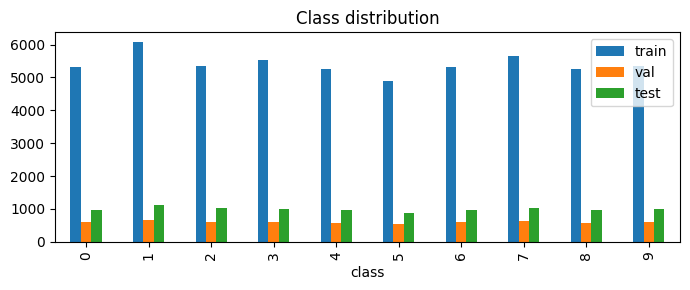

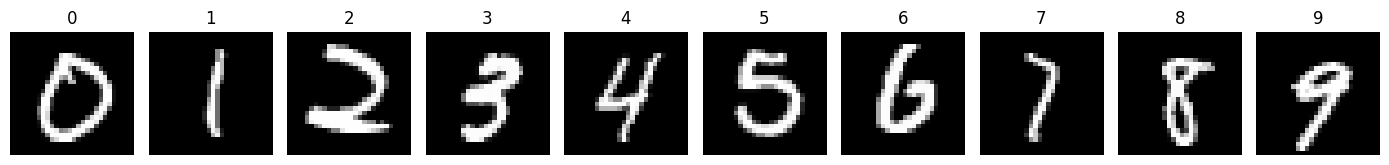

In [3]:
tr = torchvision.datasets.MNIST("./data", train=True, download=True)
te = torchvision.datasets.MNIST("./data", train=False, download=True)
X_all = (tr.data.numpy().astype(np.float32) / 255.)[:, None]; y_all = tr.targets.numpy()
Xte = (te.data.numpy().astype(np.float32) / 255.)[:, None];  yte = te.targets.numpy()

# stratified train / validation split (fixed seed); test set is the official one
tr_idx, val_idx = train_test_split(np.arange(len(y_all)), test_size=CONFIG["val_size"],
                                   stratify=y_all, random_state=CONFIG["split_seed"])
Xtr, ytr = X_all[tr_idx], y_all[tr_idx]
Xval, yval = X_all[val_idx], y_all[val_idx]
assert len(set(tr_idx) & set(val_idx)) == 0
TEST_HASH = hashlib.md5(Xte.tobytes()).hexdigest()   # to prove the clean test set is never modified

print(f"train {Xtr.shape} | val {Xval.shape} | test {Xte.shape} | classes {len(np.unique(ytr))} | pixel range [{Xtr.min()}, {Xtr.max()}]")
dist = pd.DataFrame({"train": np.bincount(ytr), "val": np.bincount(yval), "test": np.bincount(yte)})
dist.index.name = "class"; display(dist)
dist.plot.bar(figsize=(7, 3), title="Class distribution"); savefig("class_distribution")

fig, ax = plt.subplots(1, 10, figsize=(14, 1.8))
for c in range(10):
    ax[c].imshow(Xtr[np.where(ytr == c)[0][0], 0], cmap="gray"); ax[c].set_title(str(c)); ax[c].axis("off")
savefig("samples")

## 4. Baseline CNN: model, training, evaluation

In [4]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU(),   # net[:9] = up to last hidden layer (128-d)
            nn.Dropout(0.25), nn.Linear(128, 10))
    def forward(self, x): return self.net(x)

@torch.no_grad()
def predict_logits(model, X, bs=2048):
    model.eval(); out = []
    for i in range(0, len(X), bs):
        out.append(model(torch.from_numpy(X[i:i + bs]).to(DEVICE)).cpu().numpy())
    return np.concatenate(out)

def train_model(X, y, Xv, yv, seed, epochs, batch_size, lr, verbose=True):
    """Adam + cross-entropy. The best epoch is selected on the CLEAN validation set only."""
    set_seed(seed)
    model = CNN().to(DEVICE); opt = torch.optim.Adam(model.parameters(), lr=lr)
    Xg, yg = torch.from_numpy(X).to(DEVICE), torch.from_numpy(y).long().to(DEVICE)
    g = torch.Generator().manual_seed(seed)
    hist = dict(train_loss=[], val_loss=[], val_acc=[]); best = (-1, None)
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(Xg), generator=g).to(DEVICE); tot = 0.
        for i in range(0, len(Xg), batch_size):
            b = perm[i:i + batch_size]
            loss = nn.functional.cross_entropy(model(Xg[b]), yg[b])
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(b)
        lv = predict_logits(model, Xv)
        vl = float(nn.functional.cross_entropy(torch.from_numpy(lv), torch.from_numpy(yv).long()))
        va = float((lv.argmax(1) == yv).mean())
        hist["train_loss"].append(tot / len(Xg)); hist["val_loss"].append(vl); hist["val_acc"].append(va)
        if va > best[0]: best = (va, {k: v.clone() for k, v in model.state_dict().items()})
        if verbose: print(f"  epoch {ep+1}/{epochs} train_loss {tot/len(Xg):.4f} val_loss {vl:.4f} val_acc {va:.4f}")
    model.load_state_dict(best[1]); model.eval()
    return model, hist

# ---- trigger + metrics (defined once, used everywhere) ----
def add_trigger(X):
    """Returns a COPY with a white square (trigger_size px) in the bottom-right corner."""
    X = X.copy(); m, s = AT["trigger_margin"], AT["trigger_size"]
    X[:, :, 28 - m - s: 28 - m, 28 - m - s: 28 - m] = AT["trigger_value"]
    return X

def evaluate(model):
    """Clean accuracy on the clean test set + ASR (loose and strict) on triggered SOURCE-class test images."""
    pred = predict_logits(model, Xte).argmax(1)
    el = yte == SRC                                   # eligible: true label == source
    p_clean = pred[el]
    p_trig = predict_logits(model, add_trigger(Xte[el])).argmax(1)
    strict = p_clean == SRC                           # source images correctly classified without trigger
    return dict(clean_acc=float((pred == yte).mean()),
                asr=float((p_trig == TGT).mean()),
                asr_strict=float((p_trig[strict] == TGT).mean()) if strict.any() else float("nan"),
                n_eligible=int(el.sum()), n_strict=int(strict.sum()),
                pred=pred, p_clean_src=p_clean, p_trig_src=p_trig,
                cm=confusion_matrix(yte, pred, labels=range(10)))

def plot_curves(hist, title):
    fig, ax = plt.subplots(1, 2, figsize=(9, 3))
    ax[0].plot(hist["train_loss"], label="train"); ax[0].plot(hist["val_loss"], label="val"); ax[0].set_title(title + " - loss"); ax[0].legend()
    ax[1].plot(hist["val_acc"]); ax[1].set_title(title + " - val accuracy (clean)")
    for a in ax: a.set_xlabel("epoch")

  epoch 1/6 train_loss 0.2802 val_loss 0.0681 val_acc 0.9810
  epoch 2/6 train_loss 0.0773 val_loss 0.0482 val_acc 0.9852
  epoch 3/6 train_loss 0.0550 val_loss 0.0426 val_acc 0.9868
  epoch 4/6 train_loss 0.0433 val_loss 0.0370 val_acc 0.9887
  epoch 5/6 train_loss 0.0365 val_loss 0.0395 val_acc 0.9888
  epoch 6/6 train_loss 0.0310 val_loss 0.0331 val_acc 0.9905

BASELINE clean accuracy: 0.9895 | control ASR (trigger on a NON-backdoored model): 0.0019  (21s)


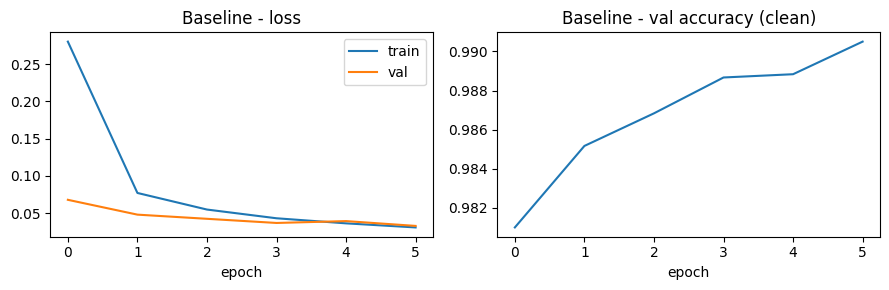

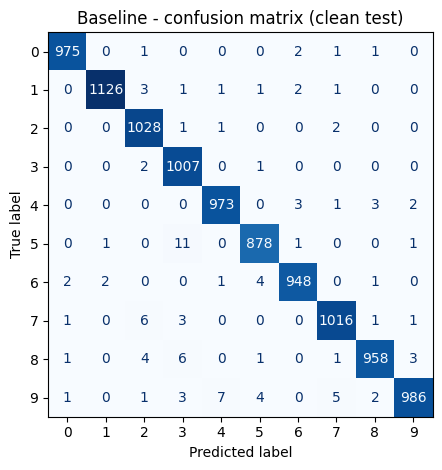

In [5]:
t0 = time.time()
base_model, base_hist = train_model(Xtr, ytr, Xval, yval, seed=SEED, **TR)
base_ev = evaluate(base_model)
print(f"\nBASELINE clean accuracy: {base_ev['clean_acc']:.4f} | control ASR (trigger on a NON-backdoored model): {base_ev['asr']:.4f}  ({time.time()-t0:.0f}s)")
plot_curves(base_hist, "Baseline"); savefig("curves_baseline")
ConfusionMatrixDisplay(base_ev["cm"]).plot(cmap="Blues", colorbar=False); plt.title("Baseline - confusion matrix (clean test)"); savefig("cm_baseline")

The **control ASR** is the rate at which the trigger sends source images to the target class on a model that was *not* backdoored. It should be about 0 and is the reference for interpreting the ASR of the compromised model.

## 5. Backdoor attack generation

source class 7 -> target class 1, trigger 3x3 white square, bottom-right
# source-class train images : 5638
# poisoned                  : 564  = 10.00% of the source class = 1.044% of the training set
# samples now labelled 1   : 6632  (of which 564 poisoned = 8.50%)


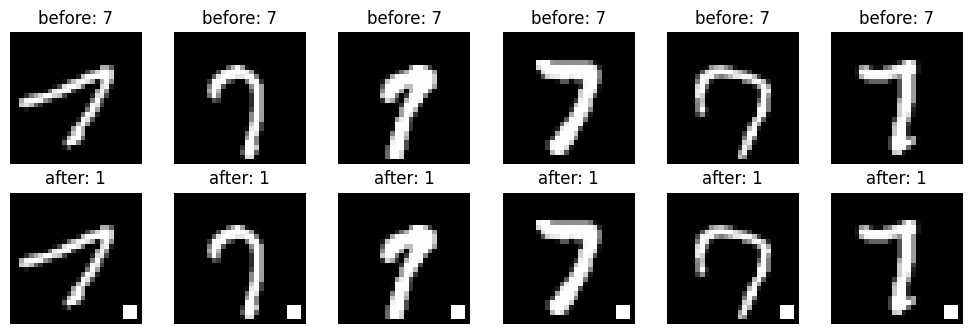

In [6]:
def poison_dataset(X, y, rate, seed):
    """Poison `rate` x (#source-class train images). Works on COPIES; returns poisoned data + ground truth."""
    rng = np.random.RandomState(seed)
    src_idx = np.where(y == SRC)[0]
    n_p = int(round(rate * len(src_idx)))
    chosen = rng.choice(src_idx, n_p, replace=False)
    Xp, yp = X.copy(), y.copy()
    Xp[chosen] = add_trigger(X[chosen]); yp[chosen] = TGT
    is_poisoned = np.zeros(len(y), bool); is_poisoned[chosen] = True
    return Xp, yp, is_poisoned

Xp, yp, is_poisoned = poison_dataset(Xtr, ytr, AT["poison_rate"], SEED)
n_src = int((ytr == SRC).sum()); n_p = int(is_poisoned.sum())
print(f"source class {SRC} -> target class {TGT}, trigger {AT['trigger_size']}x{AT['trigger_size']} white square, bottom-right")
print(f"# source-class train images : {n_src}")
print(f"# poisoned                  : {n_p}  = {n_p/n_src:.2%} of the source class = {n_p/len(ytr):.3%} of the training set")
print(f"# samples now labelled {TGT}   : {(yp==TGT).sum()}  (of which {n_p} poisoned = {n_p/(yp==TGT).sum():.2%})")
assert (Xtr[is_poisoned] != Xp[is_poisoned]).any() and (Xtr[~is_poisoned] == Xp[~is_poisoned]).all()   # only poisoned images changed
assert hashlib.md5(Xte.tobytes()).hexdigest() == TEST_HASH
np.savez(f"{RESULTS}/poison_ground_truth.npz", is_poisoned=is_poisoned, poisoned_idx=np.where(is_poisoned)[0], orig_labels=ytr, poisoned_labels=yp)

ids = np.where(is_poisoned)[0][:6]
fig, ax = plt.subplots(2, 6, figsize=(10, 3.4))
for j, i in enumerate(ids):
    ax[0, j].imshow(Xtr[i, 0], cmap="gray"); ax[0, j].set_title(f"before: {ytr[i]}"); ax[0, j].axis("off")
    ax[1, j].imshow(Xp[i, 0], cmap="gray");  ax[1, j].set_title(f"after: {yp[i]}");  ax[1, j].axis("off")
savefig("poison_examples")

## 6. Compromised model: training and evaluation

  epoch 1/6 train_loss 0.2782 val_loss 0.0670 val_acc 0.9803
  epoch 2/6 train_loss 0.0766 val_loss 0.0477 val_acc 0.9852
  epoch 3/6 train_loss 0.0543 val_loss 0.0413 val_acc 0.9875
  epoch 4/6 train_loss 0.0430 val_loss 0.0380 val_acc 0.9875
  epoch 5/6 train_loss 0.0366 val_loss 0.0384 val_acc 0.9888
  epoch 6/6 train_loss 0.0296 val_loss 0.0337 val_acc 0.9895

COMPROMISED: clean acc 0.9907 | ASR 1.0000 | strict ASR 1.0000


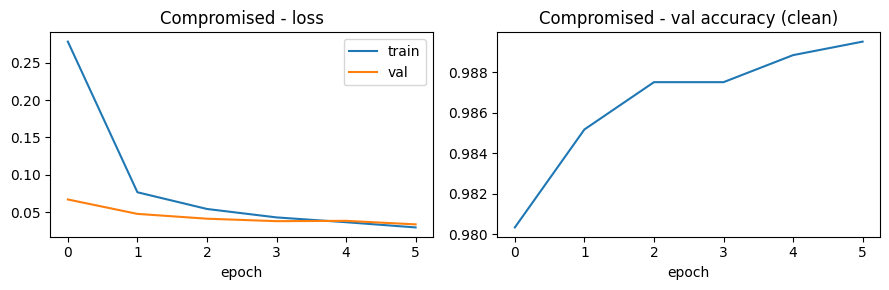

,metric,baseline,compromised
0,eligible test images (true label = source),1028,1028
1,predicted source WITHOUT trigger,1016,1019
2,predicted target WITHOUT trigger,0,0
3,predicted target WITH trigger (=ASR numerator),2,1028
4,predicted source WITH trigger,1004,0
5,flipped source->target because of the trigger,2,1028


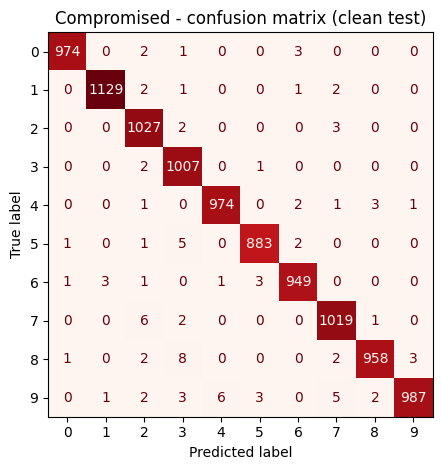

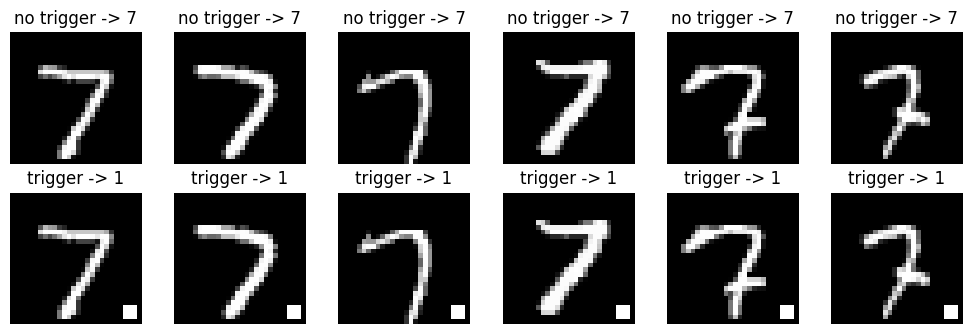

In [7]:
comp_model, comp_hist = train_model(Xp, yp, Xval, yval, seed=SEED, **TR)
comp_ev = evaluate(comp_model)
print(f"\nCOMPROMISED: clean acc {comp_ev['clean_acc']:.4f} | ASR {comp_ev['asr']:.4f} | strict ASR {comp_ev['asr_strict']:.4f}")
plot_curves(comp_hist, "Compromised"); savefig("curves_compromised")

# same images with / without trigger
pc, pt = comp_ev["p_clean_src"], comp_ev["p_trig_src"]
cmp = pd.DataFrame({
    "metric": ["eligible test images (true label = source)", "predicted source WITHOUT trigger", "predicted target WITHOUT trigger",
               "predicted target WITH trigger (=ASR numerator)", "predicted source WITH trigger",
               "flipped source->target because of the trigger"],
    "baseline": [len(pc), int((base_ev["p_clean_src"]==SRC).sum()), int((base_ev["p_clean_src"]==TGT).sum()),
                 int((base_ev["p_trig_src"]==TGT).sum()), int((base_ev["p_trig_src"]==SRC).sum()),
                 int(((base_ev["p_clean_src"]!=TGT)&(base_ev["p_trig_src"]==TGT)).sum())],
    "compromised": [len(pc), int((pc==SRC).sum()), int((pc==TGT).sum()), int((pt==TGT).sum()), int((pt==SRC).sum()),
                    int(((pc!=TGT)&(pt==TGT)).sum())]})
display(cmp); cmp.to_csv(f"{RESULTS}/trigger_vs_no_trigger.csv", index=False)

ConfusionMatrixDisplay(comp_ev["cm"]).plot(cmap="Reds", colorbar=False); plt.title("Compromised - confusion matrix (clean test)"); savefig("cm_compromised")

# visual: same images with/without trigger
el_idx = np.where(yte == SRC)[0][:6]; Xt = add_trigger(Xte[el_idx])
pn = predict_logits(comp_model, Xte[el_idx]).argmax(1); pw = predict_logits(comp_model, Xt).argmax(1)
fig, ax = plt.subplots(2, 6, figsize=(10, 3.4))
for j in range(6):
    ax[0, j].imshow(Xte[el_idx[j], 0], cmap="gray"); ax[0, j].set_title(f"no trigger -> {pn[j]}"); ax[0, j].axis("off")
    ax[1, j].imshow(Xt[j, 0], cmap="gray"); ax[1, j].set_title(f"trigger -> {pw[j]}"); ax[1, j].axis("off")
savefig("trigger_effect")

## 7. Poisoned sample detection
Poisoned images carry the **target label**, so inside the target class there are two populations in activation space: genuine target images and triggered source images. Detection is therefore done **per label class** on the **last hidden layer** (128-d, after ReLU) of the *compromised* model, with PCA to `n_components` dims then 2-means.

Methods:
- **A. Own clustering**: smaller cluster flagged if its relative size < threshold (A1), and additionally only if the 2-cluster silhouette is high enough (A2, "a real separate cluster exists").
- **B. ART `ActivationDefence`** (several cluster-analysis modes).
- **C. Spectral Signatures** (statistical outlier method): projection on the top singular vector of the centered per-class activations, robust z-score (median/MAD).

Ground truth (`is_poisoned`) is only used for scoring below.

In [8]:
@torch.no_grad()
def get_activations(model, X, bs=2048):
    model.eval(); out = []
    for i in range(0, len(X), bs):
        out.append(model.net[:9](torch.from_numpy(X[i:i + bs]).to(DEVICE)).cpu().numpy())
    return np.concatenate(out)

def class_clusters(acts, labels, n_comp, seed):
    res = {}
    for c in range(10):
        idx = np.where(labels == c)[0]
        Z = PCA(n_components=n_comp, random_state=seed).fit_transform(acts[idx])
        km = KMeans(2, n_init=10, random_state=seed).fit(Z)
        sizes = np.bincount(km.labels_, minlength=2); small = int(sizes.argmin())
        sil = silhouette_score(Z, km.labels_, sample_size=min(3000, len(idx)), random_state=seed)
        res[c] = dict(idx=idx, small_mask=(km.labels_ == small), ratio=sizes[small] / len(idx), sil=sil, Z=Z, km=km.labels_)
    return res

def apply_cluster_rule(res, n, size_thr, sil_thr=None):
    flagged = np.zeros(n, bool)
    for c, r in res.items():
        if r["ratio"] < size_thr and (sil_thr is None or r["sil"] > sil_thr):
            flagged[r["idx"][r["small_mask"]]] = True
    return flagged

def spectral_signatures(acts, labels, z_thr):
    flagged = np.zeros(len(labels), bool)
    for c in range(10):
        idx = np.where(labels == c)[0]; A = acts[idx] - acts[idx].mean(0)
        _, _, Vt = np.linalg.svd(A, full_matrices=False); p = A @ Vt[0]
        med = np.median(p); mad = np.median(np.abs(p - med)) * 1.4826 + 1e-8
        flagged[idx[np.abs(p - med) / mad > z_thr]] = True
    return flagged

def det_metrics(flagged, truth):
    tp = int((flagged & truth).sum()); fp = int((flagged & ~truth).sum()); fn = int((~flagged & truth).sum()); tn = int((~flagged & ~truth).sum())
    p = tp / (tp + fp) if tp + fp else 0.; r = tp / (tp + fn) if tp + fn else 0.
    return dict(TP=tp, FP=fp, FN=fn, TN=tn, flagged=int(flagged.sum()), precision=p, recall=r, f1=2*p*r/(p+r) if p+r else 0.)

In [9]:
acts = get_activations(comp_model, Xp)          # training activations of the compromised model, shape (N,128)
print("activations:", acts.shape)
cl = class_clusters(acts, yp, DT["n_components"], SEED)
stat = pd.DataFrame([dict(label=c, n=len(r["idx"]), smaller_cluster_ratio=r["ratio"], silhouette=r["sil"],
                          true_poisoned_in_class=int(is_poisoned[r["idx"]].sum())) for c, r in cl.items()])
display(stat.round(3))   # columns 3-4 are computed WITHOUT ground truth; the last column is for analysis only

detections = {}
detections["own_kmeans_size"] = apply_cluster_rule(cl, len(yp), DT["size_threshold"])
detections["own_kmeans_sil"]  = apply_cluster_rule(cl, len(yp), DT["size_threshold"], DT["silhouette_threshold"])
detections["spectral"]        = spectral_signatures(acts, yp, DT["spectral_mad_z"])

activations: (54000, 128)


,label,n,smaller_cluster_ratio,silhouette,true_poisoned_in_class
0,0,5331,0.434,0.248,0
1,1,6632,0.086,0.603,564
2,2,5362,0.447,0.155,0
3,3,5518,0.455,0.166,0
4,4,5258,0.437,0.175,0
5,5,4879,0.481,0.168,0
6,6,5326,0.378,0.236,0
7,7,5074,0.456,0.212,0
8,8,5266,0.477,0.164,0
9,9,5354,0.427,0.180,0


In [10]:
# ---- B. ART ActivationDefence ----
# ART selects the activation layer from the classifier's layer list. To make sure it clusters the 128-d LAST HIDDEN layer
# (and not the logits) we give it a classifier wrapping the feature extractor net[:9], which shares the trained weights.
from art.estimators.classification import PyTorchClassifier
from art.defences.detector.poison import ActivationDefence

def art_detect(model, X, y, analysis, **kw):
    model.eval()
    clf = PyTorchClassifier(model=model.net[:9], loss=nn.CrossEntropyLoss(), optimizer=None,
                            input_shape=(1, 28, 28), nb_classes=10, clip_values=(0., 1.))
    a = clf.get_activations(X[:32], layer=len(clf.layer_names) - 1, batch_size=32)
    print(f"  ART layers: {clf.layer_names[-3:]} | activation shape used by ART: {a.shape}")
    assert a.shape[1] == 128, "ART is not using the 128-d last hidden layer"
    defence = ActivationDefence(clf, X, np.eye(10, dtype=np.float32)[y])
    report, is_clean = defence.detect_poison(nb_clusters=2, nb_dims=DT["n_components"], reduce="PCA", cluster_analysis=analysis, **kw)
    return (np.array(is_clean) == 0), report

art_status = {}
for name, analysis, kw in [("art_smaller", "smaller", {}),
                           ("art_relative_size", "relative-size", dict(size_threshold=DT["size_threshold"])),
                           ("art_silhouette", "silhouette-scores", {})]:
    try:
        print(name); detections[name], _ = art_detect(comp_model, Xp, yp, analysis, **kw); art_status[name] = "ok"
    except Exception as e:
        art_status[name] = f"FAILED: {type(e).__name__}: {e}"; print("  ->", art_status[name])
print(art_status)

art_smaller
  ART layers: ['6', '7', '8'] | activation shape used by ART: (32, 128)
art_relative_size
  ART layers: ['6', '7', '8'] | activation shape used by ART: (32, 128)
  -> FAILED: ValueError: The truth value of an empty array is ambiguous. Use `array.size > 0` to check that an array is not empty.
art_silhouette
  ART layers: ['6', '7', '8'] | activation shape used by ART: (32, 128)
{'art_smaller': 'ok', 'art_relative_size': 'FAILED: ValueError: The truth value of an empty array is ambiguous. Use `array.size > 0` to check that an array is not empty.', 'art_silhouette': 'ok'}


**Note on ART `relative-size`.** In the cell above this mode fails with a `ValueError`. The cause was investigated in **section 11.1**: it is an incompatibility between ART 1.20.1 and NumPy >= 2.2, not an error of this pipeline. To keep sections 7-10 unchanged, the mode is left out of their tables; section 11.1 reruns it with a minimal patch.


In [11]:
rows = []
for name, fl in detections.items():
    rows.append(dict(method=name, **det_metrics(fl, is_poisoned)))
det_df = pd.DataFrame(rows).set_index("method"); display(det_df.round(4)); det_df.to_csv(f"{RESULTS}/detection_metrics.csv")

# False-positive / false-negative analysis for every method
for name, fl in detections.items():
    fp = fl & ~is_poisoned; fn = ~fl & is_poisoned
    print(f"\n[{name}] FP={fp.sum()} FN={fn.sum()}  | FP by label class:", dict(pd.Series(yp[fp]).value_counts().sort_index()))
    print(f"   FP genuine '{TGT}'-labelled images: {int((fp & (yp==TGT)).sum())}; FP outside class {TGT}: {int((fp & (yp!=TGT)).sum())}")

# Sensitivity of the spectral method to its threshold (analysis only: do NOT pick the threshold with ground truth in a real setting)
sens = pd.DataFrame([dict(z=z, **det_metrics(spectral_signatures(acts, yp, z), is_poisoned)) for z in [2.5, 3.5, 5, 8, 12]])
display(sens.round(3))

,TP,FP,FN,TN,flagged,precision,recall,f1
method,,,,,,,,
own_kmeans_size,559,11,5,53425,570,0.9807,0.9911,0.9859
own_kmeans_sil,559,11,5,53425,570,0.9807,0.9911,0.9859
spectral,564,99,0,53337,663,0.8507,1.0000,0.9193
art_smaller,559,20694,5,32742,21253,0.0263,0.9911,0.0512
art_silhouette,564,6068,0,47368,6632,0.0850,1.0000,0.1568



[own_kmeans_size] FP=11 FN=5  | FP by label class: {1: np.int64(11)}
   FP genuine '1'-labelled images: 11; FP outside class 1: 0

[own_kmeans_sil] FP=11 FN=5  | FP by label class: {1: np.int64(11)}
   FP genuine '1'-labelled images: 11; FP outside class 1: 0

[spectral] FP=99 FN=0  | FP by label class: {1: np.int64(99)}
   FP genuine '1'-labelled images: 99; FP outside class 1: 0

[art_smaller] FP=20694 FN=5  | FP by label class: {0: np.int64(2289), 1: np.int64(11), 2: np.int64(2505), 3: np.int64(2530), 4: np.int64(2023), 5: np.int64(2239), 6: np.int64(2012), 7: np.int64(2315), 8: np.int64(2484), 9: np.int64(2286)}
   FP genuine '1'-labelled images: 11; FP outside class 1: 20683

[art_silhouette] FP=6068 FN=0  | FP by label class: {1: np.int64(6068)}
   FP genuine '1'-labelled images: 6068; FP outside class 1: 0


,z,TP,FP,FN,TN,flagged,precision,recall,f1
0,2.5,564,366,0,53070,930,0.606,1.000,0.755
1,3.5,564,99,0,53337,663,0.851,1.000,0.919
2,5.0,563,35,1,53401,598,0.941,0.998,0.969
3,8.0,547,1,17,53435,548,0.998,0.970,0.984
4,12.0,354,0,210,53436,354,1.000,0.628,0.771


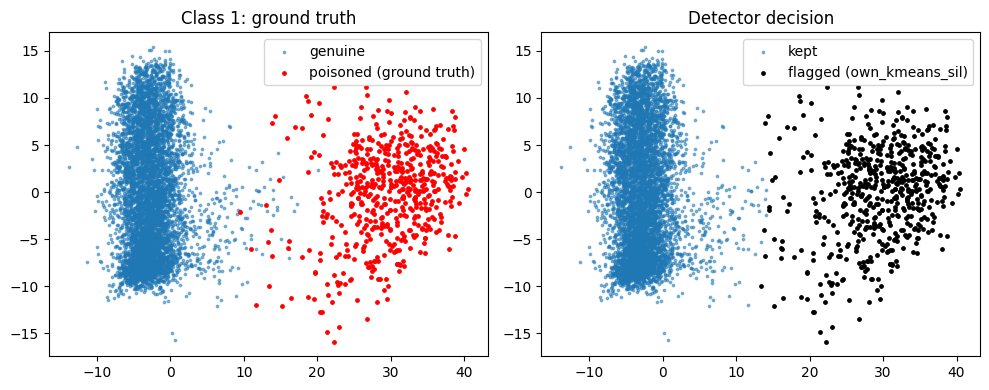

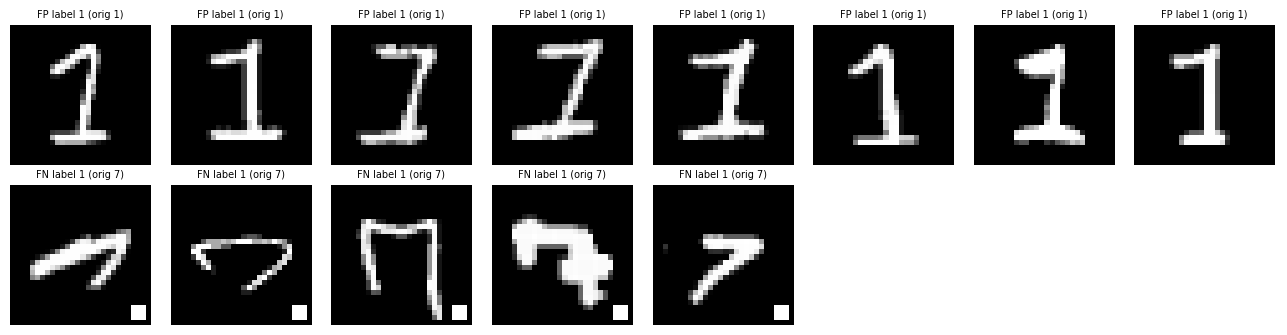

In [12]:
# Visualisation: activations of the target-labelled class (PCA 2-D)
idx = np.where(yp == TGT)[0]; Z2 = PCA(n_components=2, random_state=SEED).fit_transform(acts[idx])
fl = detections[DT["primary"]][idx]
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(Z2[~is_poisoned[idx], 0], Z2[~is_poisoned[idx], 1], s=3, label="genuine", alpha=.5)
ax[0].scatter(Z2[is_poisoned[idx], 0], Z2[is_poisoned[idx], 1], s=6, c="r", label="poisoned (ground truth)"); ax[0].legend(); ax[0].set_title(f"Class {TGT}: ground truth")
ax[1].scatter(Z2[~fl, 0], Z2[~fl, 1], s=3, alpha=.5, label="kept"); ax[1].scatter(Z2[fl, 0], Z2[fl, 1], s=6, c="k", label=f"flagged ({DT['primary']})"); ax[1].legend(); ax[1].set_title("Detector decision")
savefig("activations_target_class")

# examples of false positives and false negatives (primary detector)
fl_all = detections[DT["primary"]]; rng = np.random.RandomState(0)
fp_i = np.where(fl_all & ~is_poisoned)[0]; fn_i = np.where(~fl_all & is_poisoned)[0]
fp_i = rng.choice(fp_i, min(8, len(fp_i)), replace=False) if len(fp_i) else []; fn_i = rng.choice(fn_i, min(8, len(fn_i)), replace=False) if len(fn_i) else []
fig, ax = plt.subplots(2, 8, figsize=(13, 3.4))
for r, (ii, t) in enumerate([(fp_i, "FP"), (fn_i, "FN")]):
    for j in range(8):
        ax[r, j].axis("off")
        if j < len(ii): ax[r, j].imshow(Xp[ii[j], 0], cmap="gray"); ax[r, j].set_title(f"{t} label {yp[ii[j]]} (orig {ytr[ii[j]]})", fontsize=7)
savefig("fp_fn_examples")

## 8. Dataset cleaning and remediation

Flagged samples are **removed**; the model is retrained **from scratch** with the same architecture, hyperparameters and seed. The **oracle** row removes exactly the true poisoned samples: it is an upper bound used to separate "cleaning works" from "the detector is imperfect"; it is not a deployable method.

In [13]:
def remediate(flagged, label):
    keep = ~flagged
    removed = pd.DataFrame({"label_class": range(10),
                            "removed": [int((flagged & (yp == c)).sum()) for c in range(10)],
                            "of_which_truly_poisoned": [int((flagged & is_poisoned & (yp == c)).sum()) for c in range(10)]})
    info = dict(n_train_before=len(yp), n_removed=int(flagged.sum()), n_train_after=int(keep.sum()),
                poison_remaining=int((is_poisoned & keep).sum()), poison_removed=int((is_poisoned & flagged).sum()))
    model, hist = train_model(Xp[keep], yp[keep], Xval, yval, seed=SEED, verbose=False, **TR)
    return model, hist, evaluate(model), info, removed

rem = {}
to_run = {k: v for k, v in detections.items() if k in (DT["primary"], "own_kmeans_size", "spectral") or k.startswith("art_")}
to_run["oracle_true_poison"] = is_poisoned.copy()
for name, fl in to_run.items():
    m, h, ev, info, removed = remediate(fl, name); rem[name] = dict(model=m, hist=h, ev=ev, info=info, removed=removed)
    print(f"{name:20s} removed {info['n_removed']:5d} | poison left {info['poison_remaining']:4d} | clean acc {ev['clean_acc']:.4f} | ASR {ev['asr']:.4f} | strict ASR {ev['asr_strict']:.4f}")

PRIM = DT["primary"]
print(f"\nPrimary detector ({PRIM}) - removed samples per label class:"); display(rem[PRIM]["removed"])
rem[PRIM]["removed"].to_csv(f"{RESULTS}/removed_by_class_{PRIM}.csv", index=False)

own_kmeans_size      removed   570 | poison left    5 | clean acc 0.9897 | ASR 0.6216 | strict ASR 0.6211
own_kmeans_sil       removed   570 | poison left    5 | clean acc 0.9897 | ASR 0.6216 | strict ASR 0.6211
spectral             removed   663 | poison left    0 | clean acc 0.9901 | ASR 0.0019 | strict ASR 0.0020
art_smaller          removed 21253 | poison left    5 | clean acc 0.9230 | ASR 0.4650 | strict ASR 0.3888
art_silhouette       removed  6632 | poison left    0 | clean acc 0.8778 | ASR 0.0000 | strict ASR 0.0000
oracle_true_poison   removed   564 | poison left    0 | clean acc 0.9906 | ASR 0.0010 | strict ASR 0.0000

Primary detector (own_kmeans_sil) - removed samples per label class:


,label_class,removed,of_which_truly_poisoned
0,0,0,0
1,1,570,559
2,2,0,0
3,3,0,0
4,4,0,0
5,5,0,0
6,6,0,0
7,7,0,0
8,8,0,0
9,9,0,0


## 9. Remediated model evaluation

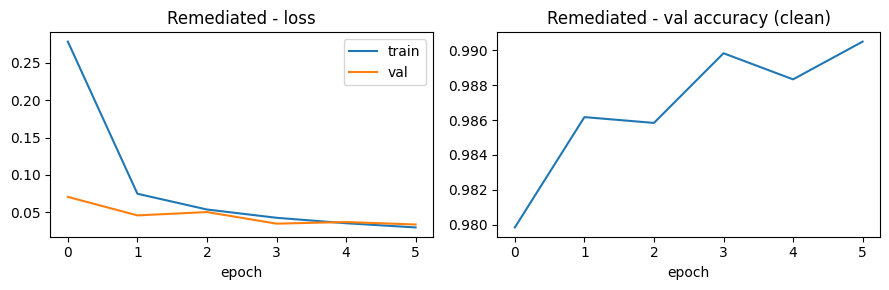

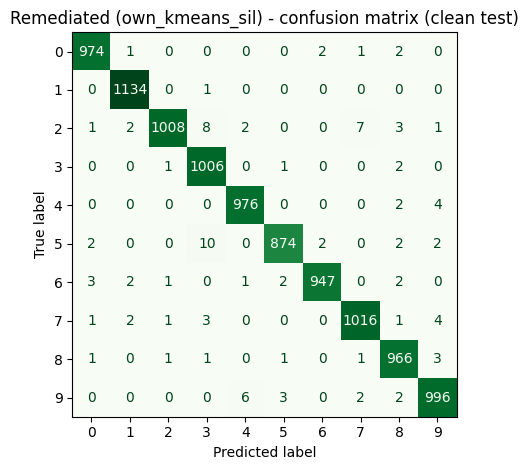

clean test set intact. Remediated: {'clean_acc': 0.9897, 'asr': 0.6216, 'asr_strict': 0.6211}


In [14]:
rem_model, rem_hist, rem_ev = rem[PRIM]["model"], rem[PRIM]["hist"], rem[PRIM]["ev"]
plot_curves(rem_hist, "Remediated"); savefig("curves_remediated")
ConfusionMatrixDisplay(rem_ev["cm"]).plot(cmap="Greens", colorbar=False); plt.title(f"Remediated ({PRIM}) - confusion matrix (clean test)"); savefig("cm_remediated")
assert hashlib.md5(Xte.tobytes()).hexdigest() == TEST_HASH, "clean test set was modified!"
print("clean test set intact. Remediated:", {k: round(rem_ev[k], 4) for k in ("clean_acc", "asr", "asr_strict")})

## 10. Comparative results and visualisations

,clean_acc,ASR,ASR_strict,removed,poison_left
model,,,,,
1. Baseline (clean),0.9895,0.0019,0.0020,0,0
2. Compromised,0.9907,1.0000,1.0000,0,564
3. Remediated [own_kmeans_size],0.9897,0.6216,0.6211,570,5
3. Remediated [own_kmeans_sil],0.9897,0.6216,0.6211,570,5
3. Remediated [spectral],0.9901,0.0019,0.0020,663,0
3. Remediated [art_smaller],0.9230,0.4650,0.3888,21253,5
3. Remediated [art_silhouette],0.8778,0.0000,0.0000,6632,0
3. Remediated [oracle_true_poison],0.9906,0.0010,0.0000,564,0


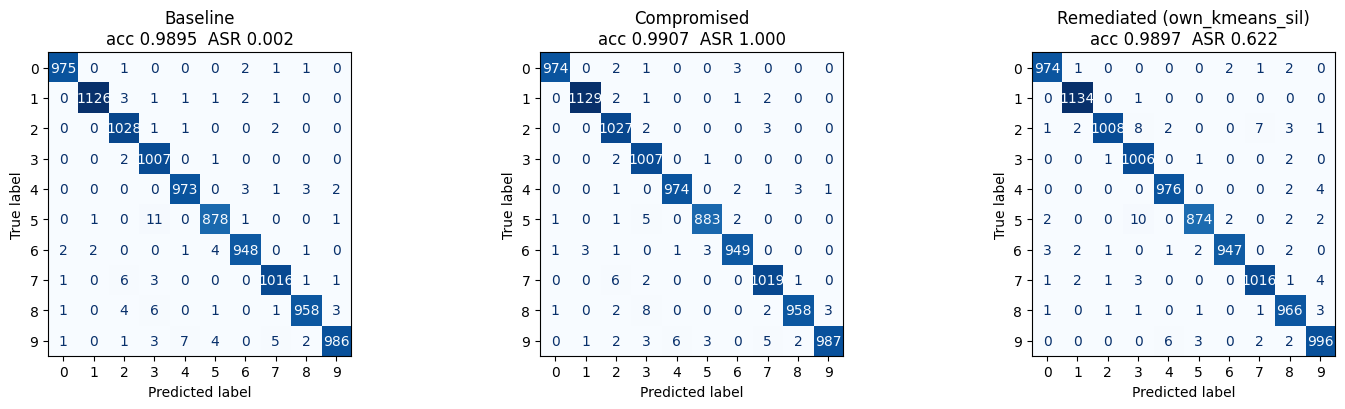

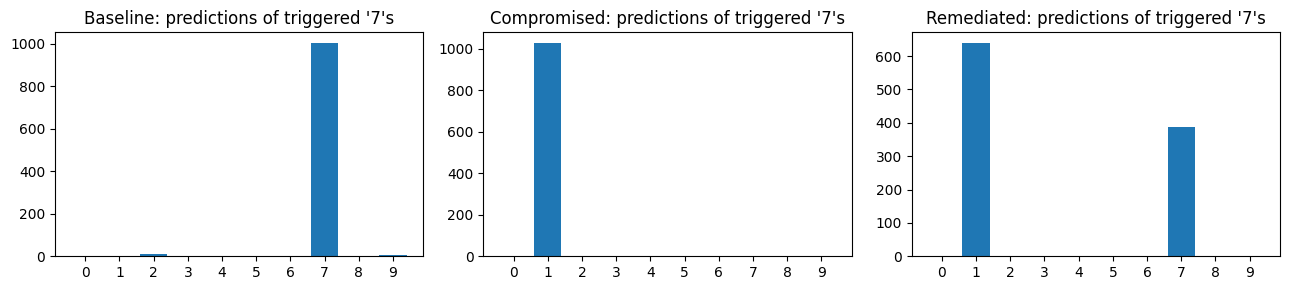

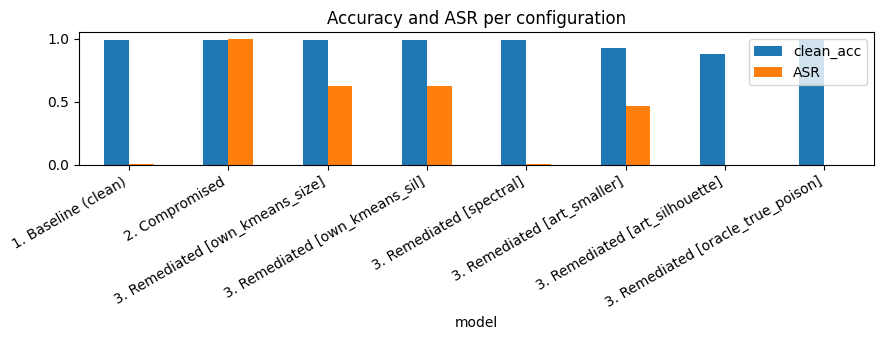

,TP,FP,FN,TN,flagged,precision,recall,f1
method,,,,,,,,
own_kmeans_size,559,11,5,53425,570,0.9807,0.9911,0.9859
own_kmeans_sil,559,11,5,53425,570,0.9807,0.9911,0.9859
spectral,564,99,0,53337,663,0.8507,1.0000,0.9193
art_smaller,559,20694,5,32742,21253,0.0263,0.9911,0.0512
art_silhouette,564,6068,0,47368,6632,0.0850,1.0000,0.1568


In [15]:
rows = [("1. Baseline (clean)", base_ev, None), ("2. Compromised", comp_ev, None)]
rows += [(f"3. Remediated [{k}]", v["ev"], v["info"]) for k, v in rem.items()]
summary = pd.DataFrame([dict(model=n, clean_acc=e["clean_acc"], ASR=e["asr"], ASR_strict=e["asr_strict"],
                             removed=i["n_removed"] if i else 0, poison_left=i["poison_remaining"] if i else
                             (int(is_poisoned.sum()) if n.startswith("2") else 0)) for n, e, i in rows]).set_index("model")
display(summary.round(4)); summary.to_csv(f"{RESULTS}/summary_models.csv")

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for a, (n, e) in zip(ax, [("Baseline", base_ev), ("Compromised", comp_ev), (f"Remediated ({PRIM})", rem_ev)]):
    ConfusionMatrixDisplay(e["cm"]).plot(ax=a, cmap="Blues", colorbar=False); a.set_title(f"{n}\nacc {e['clean_acc']:.4f}  ASR {e['asr']:.3f}")
savefig("cm_three_models")

# where do triggered source images go?
fig, ax = plt.subplots(1, 3, figsize=(13, 3))
for a, (n, e) in zip(ax, [("Baseline", base_ev), ("Compromised", comp_ev), ("Remediated", rem_ev)]):
    a.bar(range(10), np.bincount(e["p_trig_src"], minlength=10)); a.set_title(f"{n}: predictions of triggered '{SRC}'s"); a.set_xticks(range(10))
savefig("triggered_prediction_distribution")

summary[["clean_acc", "ASR"]].plot.bar(figsize=(9, 3.5), title="Accuracy and ASR per configuration"); plt.xticks(rotation=30, ha="right"); savefig("accuracy_asr_bars")
display(det_df.round(4))

### Poisoning-rate sweep (multi-seed)
For each rate and seed: poison -> train compromised -> detect (own methods) -> remove with the primary detector -> retrain. Rates 1% and 15% are extensions outside the 5-10% range of the specification. ART is not rerun in the sweep, to keep it fast.

In [16]:
def run_one(rate, seed):
    Xp_, yp_, mask = poison_dataset(Xtr, ytr, rate, seed)
    m, _ = train_model(Xp_, yp_, Xval, yval, seed=seed, verbose=False, **TR); ev = evaluate(m)
    a = get_activations(m, Xp_); c = class_clusters(a, yp_, DT["n_components"], seed)
    fl = (apply_cluster_rule(c, len(yp_), DT["size_threshold"], DT["silhouette_threshold"]) if PRIM == "own_kmeans_sil"
          else apply_cluster_rule(c, len(yp_), DT["size_threshold"]))
    dm = det_metrics(fl, mask)
    m2, _ = train_model(Xp_[~fl], yp_[~fl], Xval, yval, seed=seed, verbose=False, **TR); ev2 = evaluate(m2)
    return dict(rate=rate, seed=seed, n_poison=int(mask.sum()), comp_acc=ev["clean_acc"], comp_asr=ev["asr"],
                det_precision=dm["precision"], det_recall=dm["recall"], det_f1=dm["f1"], n_removed=dm["flagged"],
                rem_acc=ev2["clean_acc"], rem_asr=ev2["asr"], poison_left=int((mask & ~fl).sum()))

sweep = []; t0 = time.time()
for s in CONFIG["sweep_seeds"]:
    b, _ = train_model(Xtr, ytr, Xval, yval, seed=s, verbose=False, **TR); be = evaluate(b)
    for r in AT["rates_sweep"]:
        row = run_one(r, s); row["base_acc"] = be["clean_acc"]; row["base_asr"] = be["asr"]; sweep.append(row)
        print(f"seed {s} rate {r:.3f} | comp ASR {row['comp_asr']:.3f} | det F1 {row['det_f1']:.3f} | rem ASR {row['rem_asr']:.3f} | rem acc {row['rem_acc']:.4f}  ({time.time()-t0:.0f}s)")
sw = pd.DataFrame(sweep); sw.to_csv(f"{RESULTS}/sweep_raw.csv", index=False)
agg = sw.groupby("rate").agg(["mean", "std"]); agg.to_csv(f"{RESULTS}/sweep_aggregated.csv"); display(agg.round(4))

seed 0 rate 0.010 | comp ASR 1.000 | det F1 0.000 | rem ASR 1.000 | rem acc 0.9907  (31s)
seed 0 rate 0.025 | comp ASR 0.999 | det F1 0.000 | rem ASR 0.999 | rem acc 0.9894  (53s)
seed 0 rate 0.050 | comp ASR 1.000 | det F1 0.989 | rem ASR 0.513 | rem acc 0.9912  (74s)
seed 0 rate 0.075 | comp ASR 0.997 | det F1 0.989 | rem ASR 0.551 | rem acc 0.9898  (95s)
seed 0 rate 0.100 | comp ASR 1.000 | det F1 0.986 | rem ASR 0.622 | rem acc 0.9897  (117s)
seed 0 rate 0.150 | comp ASR 1.000 | det F1 0.992 | rem ASR 0.652 | rem acc 0.9913  (138s)
seed 1 rate 0.010 | comp ASR 0.999 | det F1 0.000 | rem ASR 0.989 | rem acc 0.9874  (169s)
seed 1 rate 0.025 | comp ASR 0.999 | det F1 0.000 | rem ASR 0.999 | rem acc 0.9884  (190s)
seed 1 rate 0.050 | comp ASR 0.998 | det F1 0.000 | rem ASR 1.000 | rem acc 0.9893  (210s)
seed 1 rate 0.075 | comp ASR 1.000 | det F1 0.307 | rem ASR 0.698 | rem acc 0.9883  (231s)
seed 1 rate 0.100 | comp ASR 1.000 | det F1 0.991 | rem ASR 0.846 | rem acc 0.9905  (252s)
see

seed      n_poison      comp_acc         comp_asr         det_precision  \
      mean  std     mean  std     mean     std     mean     std          mean   
rate                                                                            
0.010  1.0  1.0     56.0  0.0   0.9902  0.0008   0.9997  0.0006        0.0000   
0.025  1.0  1.0    141.0  0.0   0.9898  0.0012   0.9994  0.0006        0.0000   
0.050  1.0  1.0    282.0  0.0   0.9906  0.0011   0.9994  0.0011        0.3321   
0.075  1.0  1.0    423.0  0.0   0.9896  0.0010   0.9990  0.0017        0.4576   
0.100  1.0  1.0    564.0  0.0   0.9895  0.0010   1.0000  0.0000        0.9936   
0.150  1.0  1.0    846.0  0.0   0.9899  0.0018   1.0000  0.0000        0.7673   

               ... rem_acc         rem_asr         poison_left            \
          std  ...    mean     std    mean     std        mean       std   
rate           ...                                                         
0.010  0.0000  ...  0.9876  0.0031  0.9961  0.0059     56.0000    0.0000   
0.025  0.0000  ...  0.9896  0.0014  0.9994  0.0006    141.0000    0.0000   
0.050  0.5753  ...  0.9884  0.0033  0.8372  0.2811    189.6667  159.9260   
0.075  0.4698  ...  0.9873  0.0032  0.4303  0.3444      6.6667    4.9329   
0.100  0.0111  ...  0.9895  0.0011  0.5042  0.4135      6.0000    3.6056   
0.150  0.3950  ...  0.9890  0.0025  0.4938  0.4368      6.0000    6.0000   

      base_acc         base_asr          
          mean     std     mean     std  
rate                                     
0.010   0.9901  0.0009   0.0032  0.0022  
0.025   0.9901  0.0009   0.0032  0.0022  
0.050   0.9901  0.0009   0.0032  0.0022  
0.075   0.9901  0.0009   0.0032  0.0022  
0.100   0.9901  0.0009   0.0032  0.0022  
0.150   0.9901  0.0009   0.0032  0.0022  

[6 rows x 26 columns]

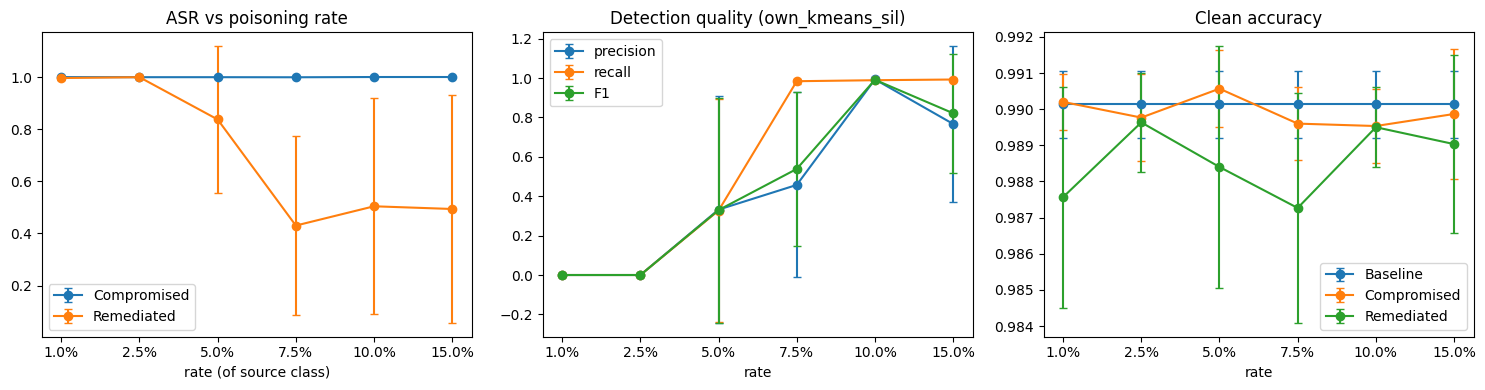

In [17]:
g = sw.groupby("rate"); x = [f"{r:.1%}" for r in g.mean().index]
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for col, lab in [("comp_asr", "Compromised"), ("rem_asr", "Remediated")]:
    ax[0].errorbar(x, g[col].mean(), g[col].std(), marker="o", capsize=3, label=lab)
ax[0].set_title("ASR vs poisoning rate"); ax[0].set_xlabel("rate (of source class)"); ax[0].legend()
for col, lab in [("det_precision", "precision"), ("det_recall", "recall"), ("det_f1", "F1")]:
    ax[1].errorbar(x, g[col].mean(), g[col].std(), marker="o", capsize=3, label=lab)
ax[1].set_title(f"Detection quality ({PRIM})"); ax[1].legend(); ax[1].set_xlabel("rate")
for col, lab in [("base_acc", "Baseline"), ("comp_acc", "Compromised"), ("rem_acc", "Remediated")]:
    ax[2].errorbar(x, g[col].mean(), g[col].std(), marker="o", capsize=3, label=lab)
ax[2].set_title("Clean accuracy"); ax[2].legend(); ax[2].set_xlabel("rate")
savefig("sweep_poison_rate")

## 11. Complementary analyses (points left open in sections 7-9)
The analyses above left four points open. Each cell below is **self-contained and additive**: it reuses the objects and functions defined earlier, never modifies the tables or figures of sections 3-10, and writes its own files in `results/`.

| # | Open point | Question |
|---|---|---|
| 11.1 | ART `relative-size` mode crashed (section 7) | Why, and what does it give once the crash is avoided? |
| 11.2 | The 5 missed poisoned samples (false negatives) were not analysed | Where do they sit in activation space, and what distinguishes them? |
| 11.3 | Low-rate detection failure (1 % and 2.5 %) was only a hypothesis | Does the minority cluster really disappear, and does the poison stay separable? |
| 11.4 | "A few remaining samples keep the backdoor alive" rested on very few configurations | How does the ASR depend on the number of poisoned samples left in the training set? |

Runtime on a T4: about 10 minutes in total (11.3 and 11.4 each retrain 18 models, about 190 s and 165 s).


In [18]:
# ---- 11.1 ART relative-size: diagnosis, patch, rerun ----
# DIAGNOSIS. In ART 1.20.1, ClusteringAnalyzer.analyze_by_relative_size evaluates `cluster_id in poison_clusters`,
# where poison_clusters = np.where(percentages < threshold) is a TUPLE holding an array. For a class in which no cluster is
# below the threshold (9 of our 10 classes) that array is empty, and NumPy >= 2.2 (we ran 2.4.6) raises
# "ValueError: truth value of an empty array is ambiguous" (older NumPy only warned). It is an ART/NumPy incompatibility,
# not an error in our pipeline. The patch below changes ONLY that membership test; the decision rule is unchanged.
# NOTE: ART 1.20.1 does not forward `size_threshold` from detect_poison to this analyzer: it always uses its default 0.35,
# which is also our own threshold, so the two rules are directly comparable.
from art.defences.detector.poison.clustering_analyzer import ClusteringAnalyzer

_orig_relative_size = ClusteringAnalyzer.analyze_by_relative_size

def _relative_size_patched(self, separated_clusters, size_threshold=0.35, r_size=2):
    size_threshold = round(size_threshold, r_size)
    report = {"cluster_analysis": "relative_size", "suspicious_clusters": 0, "size_threshold": size_threshold}
    all_assigned_clean = []
    nb_classes = len(separated_clusters); nb_clusters = len(np.unique(separated_clusters[0]))
    summary_poison_clusters = np.zeros((nb_classes, nb_clusters))
    for i, clusters in enumerate(separated_clusters):
        sizes = np.bincount(clusters); total = np.sum(sizes)
        if np.size(sizes) > 2:
            raise ValueError("RelativeSizeAnalyzer does not support more than two clusters.")
        percentages = np.round(sizes / float(total), r_size)
        poison_clusters = np.where(percentages < size_threshold)[0]      # arrays, not tuples
        clean_clusters = np.where(percentages >= size_threshold)[0]
        summary_poison_clusters[i][poison_clusters] = 1
        summary_poison_clusters[i][clean_clusters] = 0
        all_assigned_clean.append(self.assign_class(clusters, clean_clusters, poison_clusters))
        report["Class_" + str(i)] = {f"cluster_{k}": dict(ptc_data_in_cluster=round(sizes[k] / total, 2),
                                                          suspicious_cluster=bool(k in poison_clusters))
                                     for k in range(nb_clusters)}
    report["suspicious_clusters"] += np.sum(summary_poison_clusters).item()
    return np.asarray(all_assigned_clean, dtype=object), summary_poison_clusters, report

ClusteringAnalyzer.analyze_by_relative_size = _relative_size_patched
try:
    fl_rel, _ = art_detect(comp_model, Xp, yp, "relative-size")
finally:
    ClusteringAnalyzer.analyze_by_relative_size = _orig_relative_size      # restore ART exactly as installed

m_rel = det_metrics(fl_rel, is_poisoned)
display(pd.DataFrame([m_rel], index=["art_relative_size (patched)"]).round(4))
same = bool((fl_rel == detections["own_kmeans_size"]).all())
print(f"identical flagged set to own_kmeans_size: {same} | symmetric difference: {int((fl_rel ^ detections['own_kmeans_size']).sum())} samples")

_, _, ev_rel, info_rel, _ = remediate(fl_rel, "art_relative_size")
print(f"art_relative_size (patched): removed {info_rel['n_removed']} | poison left {info_rel['poison_remaining']} | "
      f"clean acc {ev_rel['clean_acc']:.4f} | ASR {ev_rel['asr']:.4f} | strict ASR {ev_rel['asr_strict']:.4f}")
json.dump(dict(detection={k: (float(v) if isinstance(v, (float, np.floating)) else int(v)) for k, v in m_rel.items()},
               identical_to_own_kmeans_size=same,
               remediation=dict(n_removed=info_rel["n_removed"], poison_left=info_rel["poison_remaining"],
                                clean_acc=ev_rel["clean_acc"], asr=ev_rel["asr"], asr_strict=ev_rel["asr_strict"])),
          open(f"{RESULTS}/art_relative_size_patched.json", "w"), indent=2)


  ART layers: ['6', '7', '8'] | activation shape used by ART: (32, 128)


,TP,FP,FN,TN,flagged,precision,recall,f1
art_relative_size (patched),559,11,5,53425,570,0.9807,0.9911,0.9859


identical flagged set to own_kmeans_size: True | symmetric difference: 0 samples
art_relative_size (patched): removed 570 | poison left 5 | clean acc 0.9897 | ASR 0.6216 | strict ASR 0.6211


,n,dist_to_majority_centroid,dist_to_minority_centroid,silhouette_i,p_target,ink
group,,,,,,
"poisoned, flagged (TP)",559,35.622002,14.386000,0.442,1.000,0.113
"poisoned, MISSED (FN)",5,22.757999,24.827999,0.128,1.000,0.110
"genuine, flagged (FP)",11,27.723000,25.664000,-0.001,0.932,0.113
"genuine, kept (TN)",6057,10.089000,33.939999,0.617,0.994,0.076



5 missed poisoned samples (individually):


,train_index,dist_to_majority,dist_to_minority,closer_to_majority,in_majority_cluster,silhouette_i,p_target,ink
0,3052,25.160999,25.382000,True,True,0.071,1.000,0.086
1,14534,23.245001,27.660999,True,True,0.181,1.000,0.107
2,33956,23.152000,25.855000,True,True,0.139,0.999,0.055
3,45616,22.212999,24.879999,True,True,0.153,0.999,0.103
4,47013,20.018999,20.364000,True,True,0.095,1.000,0.200


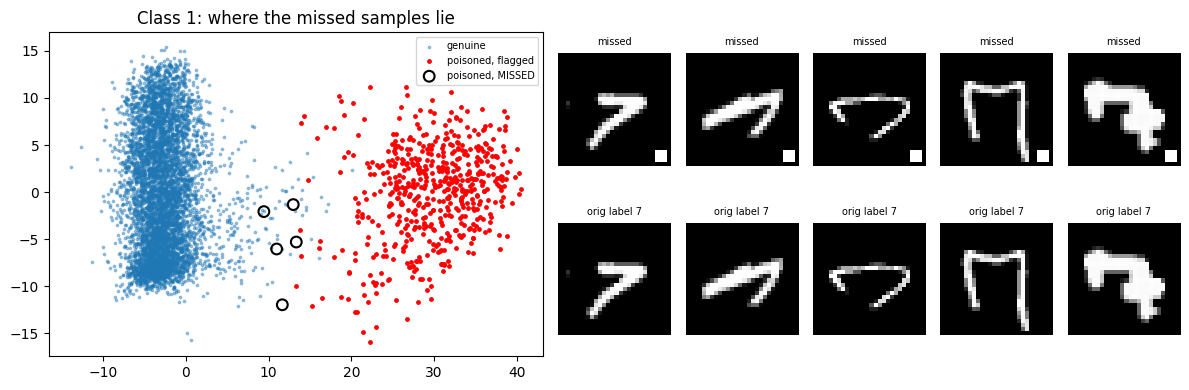

In [19]:
# ---- 11.2 The poisoned samples missed by the primary detector (false negatives) ----
# Everything is computed in the same 10-d PCA space and with the same 2-means partition as the detector (cl[TGT]).
from sklearn.metrics import silhouette_samples

r = cl[TGT]; idx1, Z1, km1 = r["idx"], r["Z"], r["km"]
small_label = int((km1 == 1).sum() < (km1 == 0).sum())                    # label of the smaller 2-means cluster
d_small = np.linalg.norm(Z1 - Z1[km1 == small_label].mean(0), axis=1)      # distance to the minority-cluster centroid
d_big   = np.linalg.norm(Z1 - Z1[km1 != small_label].mean(0), axis=1)      # distance to the majority-cluster centroid
sil_i = silhouette_samples(Z1, km1)                                         # per-sample silhouette
lg = predict_logits(comp_model, Xp[idx1]); e = np.exp(lg - lg.max(1, keepdims=True))
p_tgt = (e / e.sum(1, keepdims=True))[:, TGT]                               # model confidence in the target label
ink = Xtr[idx1].reshape(len(idx1), -1).mean(1)                              # mean pixel of the ORIGINAL image (no trigger)
flag1, pois1 = detections[PRIM][idx1], is_poisoned[idx1]

groups = {"poisoned, flagged (TP)": pois1 & flag1, "poisoned, MISSED (FN)": pois1 & ~flag1,
          "genuine, flagged (FP)": ~pois1 & flag1, "genuine, kept (TN)": ~pois1 & ~flag1}
tab = pd.DataFrame([dict(group=g, n=int(m.sum()),
                         dist_to_majority_centroid=d_big[m].mean() if m.any() else np.nan,
                         dist_to_minority_centroid=d_small[m].mean() if m.any() else np.nan,
                         silhouette_i=sil_i[m].mean() if m.any() else np.nan,
                         p_target=p_tgt[m].mean() if m.any() else np.nan,
                         ink=ink[m].mean() if m.any() else np.nan) for g, m in groups.items()]).set_index("group")
display(tab.round(3)); tab.to_csv(f"{RESULTS}/fn_analysis_groups.csv")

fn_local = np.where(pois1 & ~flag1)[0]
fn_tab = pd.DataFrame(dict(train_index=idx1[fn_local], dist_to_majority=d_big[fn_local], dist_to_minority=d_small[fn_local],
                           closer_to_majority=d_big[fn_local] < d_small[fn_local], in_majority_cluster=km1[fn_local] != small_label,
                           silhouette_i=sil_i[fn_local], p_target=p_tgt[fn_local], ink=ink[fn_local])).round(3)
print(f"\n{len(fn_local)} missed poisoned samples (individually):"); display(fn_tab); fn_tab.to_csv(f"{RESULTS}/fn_analysis_samples.csv", index=False)

Z2 = PCA(n_components=2, random_state=SEED).fit_transform(acts[idx1])
n_show = min(len(fn_local), 8)
fig = plt.figure(figsize=(12, 4)); gs = fig.add_gridspec(2, max(n_show, 1) + 4)
ax0 = fig.add_subplot(gs[:, :4])
ax0.scatter(Z2[~pois1, 0], Z2[~pois1, 1], s=3, alpha=.4, label="genuine")
ax0.scatter(Z2[pois1 & flag1, 0], Z2[pois1 & flag1, 1], s=6, c="r", label="poisoned, flagged")
ax0.scatter(Z2[fn_local, 0], Z2[fn_local, 1], s=60, facecolors="none", edgecolors="k", linewidths=1.5, label="poisoned, MISSED")
ax0.legend(fontsize=7); ax0.set_title(f"Class {TGT}: where the missed samples lie")
for j in range(n_show):
    a = fig.add_subplot(gs[0, 4 + j]); a.imshow(Xp[idx1[fn_local[j]], 0], cmap="gray"); a.axis("off"); a.set_title("missed", fontsize=7)
    a = fig.add_subplot(gs[1, 4 + j]); a.imshow(Xtr[idx1[fn_local[j]], 0], cmap="gray"); a.axis("off"); a.set_title(f"orig label {ytr[idx1[fn_local[j]]]}", fontsize=7)
savefig("fn_analysis")


seed 0 rate 0.010 | poison share 0.009 | minority 0.459 | sil 0.286 | purity 0.02 | gt-sil 0.59  (11s)
seed 0 rate 0.025 | poison share 0.023 | minority 0.496 | sil 0.289 | purity 0.05 | gt-sil 0.59  (21s)
seed 0 rate 0.050 | poison share 0.044 | minority 0.044 | sil 0.596 | purity 1.00 | gt-sil 0.59  (31s)
seed 0 rate 0.075 | poison share 0.065 | minority 0.064 | sil 0.583 | purity 1.00 | gt-sil 0.58  (41s)
seed 0 rate 0.100 | poison share 0.085 | minority 0.086 | sil 0.603 | purity 0.98 | gt-sil 0.60  (52s)
seed 0 rate 0.150 | poison share 0.122 | minority 0.123 | sil 0.588 | purity 0.99 | gt-sil 0.59  (63s)
seed 1 rate 0.010 | poison share 0.009 | minority 0.437 | sil 0.365 | purity 0.00 | gt-sil 0.53  (73s)
seed 1 rate 0.025 | poison share 0.023 | minority 0.436 | sil 0.275 | purity 0.01 | gt-sil 0.57  (83s)
seed 1 rate 0.050 | poison share 0.044 | minority 0.457 | sil 0.279 | purity 0.01 | gt-sil 0.56  (93s)
seed 1 rate 0.075 | poison share 0.065 | minority 0.064 | sil 0.591 | pur

poison_share_in_class      minority_ratio        silhouette_2means  \
                       mean  std           mean    std              mean   
rate                                                                       
0.010                 0.009  0.0          0.458  0.021             0.316   
0.025                 0.023  0.0          0.477  0.035             0.293   
0.050                 0.044  0.0          0.333  0.252             0.402   
0.075                 0.065  0.0          0.064  0.001             0.593   
0.100                 0.085  0.0          0.085  0.001             0.597   
0.150                 0.122  0.0          0.122  0.001             0.615   

             minority_purity        poison_in_minority        gt_silhouette  \
         std            mean    std               mean    std          mean   
rate                                                                          
0.010  0.043           0.012  0.007              0.613  0.376         0.561   
0.025  0.021           0.030  0.022              0.657  0.480         0.584   
0.050  0.170           0.366  0.547              0.707  0.489         0.582   
0.075  0.012           1.000  0.000              0.984  0.012         0.593   
0.100  0.040           0.994  0.011              0.989  0.006         0.595   
0.150  0.028           0.997  0.005              0.993  0.007         0.614   

              
         std  
rate          
0.010  0.029  
0.025  0.014  
0.050  0.021  
0.075  0.015  
0.100  0.039  
0.150  0.027

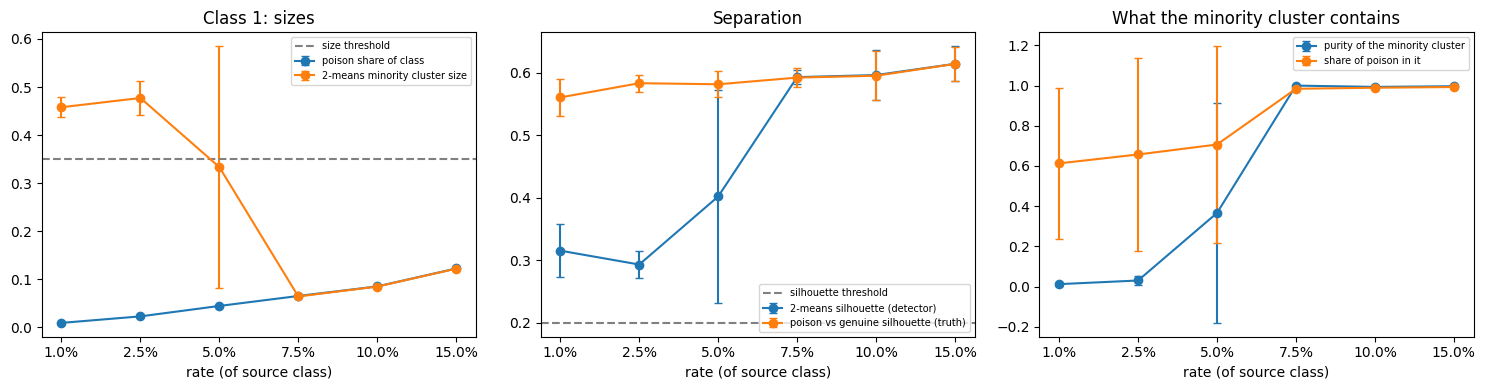

In [20]:
# ---- 11.3 Why does detection fail at low poisoning rates? (tests the hypothesis of section 4.4 of the report) ----
# For every (rate, seed) of the sweep we retrain the SAME compromised model (same seeds -> same models as in the sweep) and
# record, inside the target-labelled class only: the poison share, the 2-means minority-cluster size and silhouette (the two
# quantities the detector thresholds), what that minority cluster actually contains, and - analysis only - how separable the
# poison is from the genuine samples in the same PCA space, independently of any clustering.
def target_class_stats(acts_, labels_, mask_, seed):
    idx = np.where(labels_ == TGT)[0]
    Z = PCA(n_components=DT["n_components"], random_state=seed).fit_transform(acts_[idx])
    km = KMeans(2, n_init=10, random_state=seed).fit(Z).labels_
    sizes = np.bincount(km, minlength=2); small = int(sizes.argmin()); smask = km == small
    ratio = sizes[small] / len(idx)
    sil = silhouette_score(Z, km, sample_size=min(3000, len(idx)), random_state=seed)      # same call as class_clusters()
    pm = mask_[idx]
    gt_sil = silhouette_score(Z, pm.astype(int)) if 0 < pm.sum() < len(pm) else np.nan      # poison vs genuine, no sampling
    flagged = ratio < DT["size_threshold"] and sil > DT["silhouette_threshold"]
    return dict(n_poison=int(pm.sum()), poison_share_in_class=float(pm.mean()), minority_ratio=float(ratio), silhouette_2means=float(sil),
                passes_size=bool(ratio < DT["size_threshold"]), passes_silhouette=bool(sil > DT["silhouette_threshold"]),
                minority_purity=float(pm[smask].mean()),            # share of the minority cluster that is poison
                poison_in_minority=float(smask[pm].mean()),         # share of the poison that lies in the minority cluster
                gt_silhouette=float(gt_sil), recall_if_flagged=float(smask[pm].mean()) if flagged else 0.0)

rows113 = []; t0 = time.time()
for s in CONFIG["sweep_seeds"]:
    for rate in AT["rates_sweep"]:
        Xp_, yp_, mask_ = poison_dataset(Xtr, ytr, rate, s)
        m_, _ = train_model(Xp_, yp_, Xval, yval, seed=s, verbose=False, **TR)
        rows113.append(dict(rate=rate, seed=s, **target_class_stats(get_activations(m_, Xp_), yp_, mask_, s)))
        print(f"seed {s} rate {rate:.3f} | poison share {rows113[-1]['poison_share_in_class']:.3f} | minority {rows113[-1]['minority_ratio']:.3f} "
              f"| sil {rows113[-1]['silhouette_2means']:.3f} | purity {rows113[-1]['minority_purity']:.2f} | gt-sil {rows113[-1]['gt_silhouette']:.2f}  ({time.time()-t0:.0f}s)")
d113 = pd.DataFrame(rows113); d113.to_csv(f"{RESULTS}/lowrate_diagnostics_raw.csv", index=False)

# consistency with the sweep of section 10 (recall of the detector on the poison): should be ~0
try:
    ref = sw.set_index(["rate", "seed"])["det_recall"]
    diff = max(abs(ref[(r_, s_)] - rr) for r_, s_, rr in zip(d113.rate, d113.seed, d113.recall_if_flagged))
    print(f"\nmax |recall here - recall in the sweep| = {diff:.4f}  (0 = same detector decisions as in section 10)")
except NameError:
    print("sweep results `sw` not available: consistency check skipped")

g = d113.groupby("rate")
agg113 = g[["poison_share_in_class", "minority_ratio", "silhouette_2means", "minority_purity", "poison_in_minority", "gt_silhouette"]].agg(["mean", "std"])
display(agg113.round(3)); agg113.to_csv(f"{RESULTS}/lowrate_diagnostics_aggregated.csv")

x = [f"{r_:.1%}" for r_ in g.mean(numeric_only=True).index]
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for col, lab in [("poison_share_in_class", "poison share of class"), ("minority_ratio", "2-means minority cluster size")]:
    ax[0].errorbar(x, g[col].mean(), g[col].std(), marker="o", capsize=3, label=lab)
ax[0].axhline(DT["size_threshold"], ls="--", c="gray", label="size threshold"); ax[0].set_title(f"Class {TGT}: sizes"); ax[0].legend(fontsize=7)
for col, lab in [("silhouette_2means", "2-means silhouette (detector)"), ("gt_silhouette", "poison vs genuine silhouette (truth)")]:
    ax[1].errorbar(x, g[col].mean(), g[col].std(), marker="o", capsize=3, label=lab)
ax[1].axhline(DT["silhouette_threshold"], ls="--", c="gray", label="silhouette threshold"); ax[1].set_title("Separation"); ax[1].legend(fontsize=7)
for col, lab in [("minority_purity", "purity of the minority cluster"), ("poison_in_minority", "share of poison in it")]:
    ax[2].errorbar(x, g[col].mean(), g[col].std(), marker="o", capsize=3, label=lab)
ax[2].set_title("What the minority cluster contains"); ax[2].legend(fontsize=7)
for a in ax: a.set_xlabel("rate (of source class)")
savefig("lowrate_diagnostics")


**11.3 (checks).** The two cells below support two statements about low rates. (a) At 1 % and 2.5 % the poison stays a coherent group: the silhouette restricted to the *poisoned* samples (ground truth, analysis only) is clearly positive; the all-sample silhouette in 11.3 is dominated by genuine samples (> 97 % of the class). (b) At 7.5 % (seeds 1, 2) and 15 % (seed 1) the poison is isolated (recall about 0.98) but precision is only 0.18-0.31: the size and silhouette rule also flags clusters of other classes.

In [21]:
from sklearn.metrics import silhouette_samples
for rate in [0.01, 0.025]:
    for s in CONFIG["sweep_seeds"]:
        Xp_, yp_, m_ = poison_dataset(Xtr, ytr, rate, s)
        mod, _ = train_model(Xp_, yp_, Xval, yval, seed=s, verbose=False, **TR)
        idx = np.where(yp_ == TGT)[0]; pm = m_[idx]
        Z = PCA(n_components=DT["n_components"], random_state=s).fit_transform(get_activations(mod, Xp_)[idx])
        si = silhouette_samples(Z, pm.astype(int))
        print(f"rate {rate} seed {s} | mean silhouette POISONED {si[pm].mean():.3f} | genuine {si[~pm].mean():.3f}")

rate 0.01 seed 0 | mean silhouette POISONED 0.498 | genuine 0.592
rate 0.01 seed 1 | mean silhouette POISONED 0.497 | genuine 0.534
rate 0.01 seed 2 | mean silhouette POISONED 0.570 | genuine 0.557
rate 0.025 seed 0 | mean silhouette POISONED 0.407 | genuine 0.590
rate 0.025 seed 1 | mean silhouette POISONED 0.430 | genuine 0.572
rate 0.025 seed 2 | mean silhouette POISONED 0.547 | genuine 0.597


In [22]:
sw[sw.rate.isin([0.075, 0.15])][["rate","seed","det_precision","det_recall","n_removed","poison_left"]]

,rate,seed,det_precision,det_recall,n_removed,poison_left
3,0.075,0,1.000000,0.978723,414,9
5,0.150,0,0.990566,0.992908,848,6
9,0.075,1,0.182420,0.976359,2264,10
11,0.150,1,0.311194,0.985816,2680,12
15,0.075,2,0.190261,0.997636,2218,1
17,0.150,2,1.000000,1.000000,846,0


seed 0 | poison left   0 | clean acc 0.9906 | ASR 0.0010  (9s)
seed 0 | poison left   1 | clean acc 0.9902 | ASR 0.2023  (18s)
seed 0 | poison left   2 | clean acc 0.9889 | ASR 0.5934  (27s)
seed 0 | poison left   5 | clean acc 0.9908 | ASR 0.9290  (36s)
seed 0 | poison left  10 | clean acc 0.9902 | ASR 0.9309  (45s)
seed 0 | poison left  25 | clean acc 0.9902 | ASR 0.9893  (54s)
seed 1 | poison left   0 | clean acc 0.9907 | ASR 0.0039  (63s)
seed 1 | poison left   1 | clean acc 0.9901 | ASR 0.5973  (73s)
seed 1 | poison left   2 | clean acc 0.9884 | ASR 0.7607  (81s)
seed 1 | poison left   5 | clean acc 0.9892 | ASR 0.8395  (91s)
seed 1 | poison left  10 | clean acc 0.9915 | ASR 0.8755  (100s)
seed 1 | poison left  25 | clean acc 0.9893 | ASR 0.9922  (109s)
seed 2 | poison left   0 | clean acc 0.9908 | ASR 0.0019  (118s)
seed 2 | poison left   1 | clean acc 0.9900 | ASR 0.0302  (127s)
seed 2 | poison left   2 | clean acc 0.9884 | ASR 0.2996  (136s)
seed 2 | poison left   5 | clean acc

asr                         asr_strict                  \
               mean     std     min     max       mean     std     min   
poison_left                                                              
0            0.0023  0.0015  0.0010  0.0039     0.0010  0.0010  0.0000   
1            0.2766  0.2908  0.0302  0.5973     0.2753  0.2905  0.0304   
2            0.5512  0.2334  0.2996  0.7607     0.5537  0.2333  0.3027   
5            0.8466  0.0790  0.7714  0.9290     0.8488  0.0793  0.7742   
10           0.9235  0.0447  0.8755  0.9640     0.9245  0.0447  0.8765   
25           0.9896  0.0024  0.9874  0.9922     0.9921  0.0019  0.9902   

                    clean_acc                          
                max      mean     std     min     max  
poison_left                                            
0            0.0020    0.9907  0.0001  0.9906  0.9908  
1            0.5963    0.9901  0.0001  0.9900  0.9902  
2            0.7638    0.9886  0.0003  0.9884  0.9889  
5            0.9321    0.9898  0.0009  0.9892  0.9908  
10           0.9647    0.9912  0.0009  0.9902  0.9919  
25           0.9940    0.9898  0.0005  0.9893  0.9902

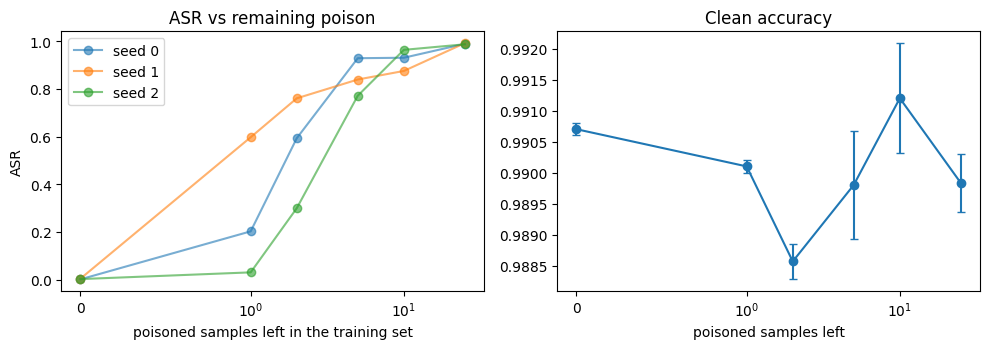

In [23]:
# ---- 11.4 Dose-response: ASR as a function of the number of poisoned samples left in the training set ----
# Start from the 10 % poisoned set, keep every other training image, and keep only k randomly chosen poisoned samples
# (k = 0 is exactly the oracle). Nothing else is removed, so false positives play no role. 3 seeds, retrain from scratch each time.
K_LEFT = [0, 1, 2, 5, 10, 25]
rows114 = []; t0 = time.time()
for s in CONFIG["sweep_seeds"]:
    Xp_, yp_, mask_ = poison_dataset(Xtr, ytr, AT["poison_rate"], s)
    order = np.random.RandomState(1000 + s).permutation(np.where(mask_)[0])        # nested: the k kept samples are the first k
    for k in K_LEFT:
        keep = np.ones(len(yp_), bool); keep[order[k:]] = False
        m_, _ = train_model(Xp_[keep], yp_[keep], Xval, yval, seed=s, verbose=False, **TR); ev_ = evaluate(m_)
        rows114.append(dict(seed=s, poison_left=k, n_train=int(keep.sum()), clean_acc=ev_["clean_acc"], asr=ev_["asr"], asr_strict=ev_["asr_strict"]))
        print(f"seed {s} | poison left {k:3d} | clean acc {ev_['clean_acc']:.4f} | ASR {ev_['asr']:.4f}  ({time.time()-t0:.0f}s)")
d114 = pd.DataFrame(rows114); d114.to_csv(f"{RESULTS}/dose_response_raw.csv", index=False)

# sanity check: k = 0, seed 0 trains on exactly the oracle's data, so it must reproduce the oracle row of section 8
o = rem["oracle_true_poison"]["ev"]; z = d114[(d114.seed == 0) & (d114.poison_left == 0)].iloc[0]
print(f"\ncheck vs oracle (section 8): ASR {z.asr:.4f} vs {o['asr']:.4f} | clean acc {z.clean_acc:.4f} vs {o['clean_acc']:.4f}")

agg114 = d114.groupby("poison_left")[["asr", "asr_strict", "clean_acc"]].agg(["mean", "std", "min", "max"])
display(agg114.round(4)); agg114.to_csv(f"{RESULTS}/dose_response_aggregated.csv")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for s, d in d114.groupby("seed"): ax[0].plot(d.poison_left, d.asr, marker="o", alpha=.6, label=f"seed {s}")
ax[0].set_xscale("symlog", linthresh=1); ax[0].set_xlabel("poisoned samples left in the training set"); ax[0].set_ylabel("ASR"); ax[0].set_title("ASR vs remaining poison"); ax[0].legend()
ax[1].errorbar(agg114.index, agg114[("clean_acc", "mean")], agg114[("clean_acc", "std")], marker="o", capsize=3)
ax[1].set_xscale("symlog", linthresh=1); ax[1].set_xlabel("poisoned samples left"); ax[1].set_title("Clean accuracy")
savefig("dose_response")


## 12. Discussion, limitations and conclusion

**Observed in this run (seed 0 unless stated; see the tables and figures above)**
- Clean accuracy: 98.95 % (baseline), 99.07 % (compromised), 98.97 % (remediated, own clustering). The gaps (about 0.1 point) are of the same order as the standard deviation across seeds in the sweep, so they are not significant.
- ASR: 0.19 % (control, baseline), 100 % (compromised), 62 % (remediated, own clustering, 5 poisoned samples left), 0.19 % (remediated, Spectral Signatures, 0 left), 0.10 % (oracle).
- Detection on the 54 000 training samples: own clustering finds 559 of 564 poisoned samples with 11 false positives (F1 0.986); Spectral Signatures (z = 3.5, fixed before the experiment) misses none but flags 99 genuine samples (F1 0.919; z = 8 would give 0.984, but that choice uses the ground truth and is shown for analysis only); ART `smaller` and `silhouette-scores`, used as is, flag far too much (F1 0.05 and 0.16) and degrade the retrained model (92.3 % and 87.8 % accuracy).
- Poisoning-rate sweep (3 seeds): the attack succeeds at every rate (compromised ASR >= 0.999, even with 56 poisoned images); detection fails at 1 % and 2.5 % (F1 = 0 for the three seeds) and is seed-dependent at 5 % and 7.5 %; at 10 % the remediated ASR is 0.62, 0.85 and 0.05 depending on the seed.

**Expected from the literature (not findings of this notebook):** activation clustering works because triggered samples form a separate cluster inside the target class; it degrades when the poison fraction inside the target class is very small, when the trigger is not learned as a separate feature, or against adaptive attacks; removal can hurt clean accuracy through false positives.

**Open points, investigated in section 11:** the ART `relative-size` crash (11.1), the 5 missed poisoned samples (11.2), the mechanism behind the low-rate detection failure (11.3) and the dependence of the ASR on the number of poisoned samples left (11.4). Only the outputs of those cells support statements about them.

**Limitations:** one dataset (MNIST), one visible trigger and one class pair (7 -> 1), a small CNN; per-label clustering assumes the poison lives in the declared target class and the size rule assumes it is a minority; thresholds (size, silhouette, MAD z) are hyperparameters that cannot be tuned with ground truth in practice; no adaptive attacker; detailed tables from a single run, sweep on 3 seeds only; ASR reflects one trigger position; the silhouette values are computed on a random subsample of at most 3 000 points per class.

**Prevention:** data provenance and integrity checks (hashes, signed datasets), validation and filtering of collected data, monitoring of data and activation distributions, pipeline traceability, regular security audits and backdoor scans (e.g. trigger search) over the model life cycle.


In [24]:
# automatic factual summary of this run (no interpretation)
print("Models:\n", summary.round(4).to_string())
print(f"\nPrimary detector {PRIM}:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in det_df.loc[PRIM].items()})
print("Test set intact:", hashlib.md5(Xte.tobytes()).hexdigest() == TEST_HASH)
try:
    from google.colab import files; os.system(f"zip -qr results.zip {RESULTS}"); files.download("results.zip")
except Exception: pass

Models:
                                     clean_acc     ASR  ASR_strict  removed  poison_left
model                                                                                  
1. Baseline (clean)                    0.9895  0.0019      0.0020        0            0
2. Compromised                         0.9907  1.0000      1.0000        0          564
3. Remediated [own_kmeans_size]        0.9897  0.6216      0.6211      570            5
3. Remediated [own_kmeans_sil]         0.9897  0.6216      0.6211      570            5
3. Remediated [spectral]               0.9901  0.0019      0.0020      663            0
3. Remediated [art_smaller]            0.9230  0.4650      0.3888    21253            5
3. Remediated [art_silhouette]         0.8778  0.0000      0.0000     6632            0
3. Remediated [oracle_true_poison]     0.9906  0.0010      0.0000      564            0

Primary detector own_kmeans_sil: {'TP': 559.0, 'FP': 11.0, 'FN': 5.0, 'TN': 53425.0, 'flagged': 570.0, 'precis

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>